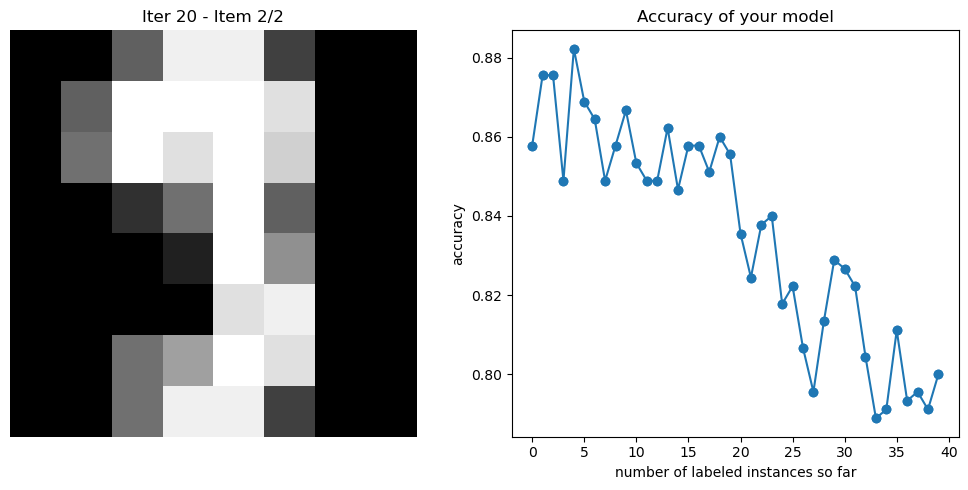

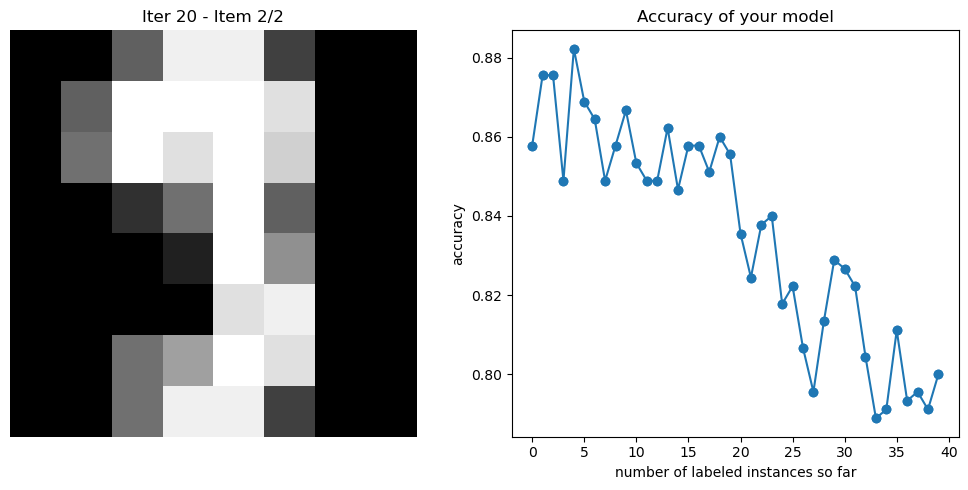


Iter 20 — instância 2/2
Which digit is this?
❌ Era 3 (disseste 8)
Acurácia: 0.7956


PermissionError: [Errno 1] Operation not permitted: 'interactive_labeling_results.png'

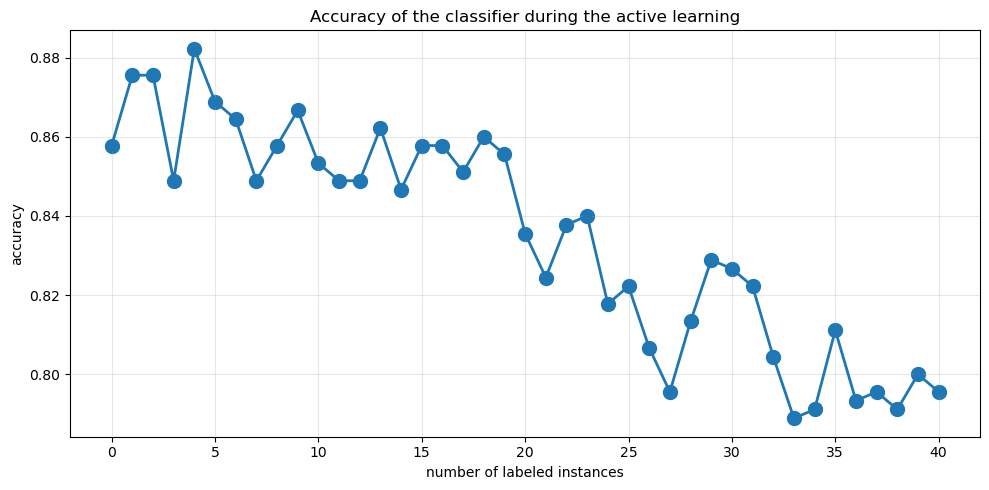

In [5]:
"""
Interactive Labeling com Active Learning - SEM modAL
====================================================
Implementação que segue EXATAMENTE o código original do notebook.
CORRIGIDO: Agora os gráficos abrem corretamente.

Autor: Adaptado de interactive_labeling.ipynb
Data: 16 de Outubro de 2025
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import warnings

from IPython.display import display, clear_output

warnings.filterwarnings("ignore")

# Configurar matplotlib para modo interativo
plt.ion()  # Ativar modo interativo

# =============================================================================
# FUNÇÕES DE ACTIVE LEARNING (substitui modAL)
# =============================================================================

def uncertainty_scores(model, X_pool):
    """Return uncertainty score (higher = more uncertain) for each pool instance."""
    proba = model.predict_proba(X_pool)
    return 1 - np.max(proba, axis=1)


class ActiveLearner:
    """
    Substitui modAL.models.ActiveLearner
    Interface idêntica ao original (query returns indices/instances)
    """

    def __init__(self, estimator, query_strategy, X_training, y_training):
        self.estimator = estimator
        self.X_training = X_training.copy()
        self.y_training = y_training.copy()
        self.estimator.fit(self.X_training, self.y_training)

    def query(self, X_pool, n_instances=1):
        """
        Seleciona os `n_instances` exemplos mais incertos do pool.
        Retorna: (query_idx_array, query_instances_array)
        """
        scores = uncertainty_scores(self.estimator, X_pool)
        n = min(n_instances, len(X_pool))
        idx = np.argsort(-scores)[:n]
        return idx, X_pool[idx]

    def teach(self, X_new, y_new):
        self.X_training = np.vstack([self.X_training, X_new])
        self.y_training = np.concatenate([self.y_training, y_new])
        self.estimator.fit(self.X_training, self.y_training)

    def score(self, X_test, y_test):
        return accuracy_score(y_test, self.estimator.predict(X_test))


# =============================================================================
# CÓDIGO ORIGINAL DO NOTEBOOK (adaptado sem modAL)
# =============================================================================

# Número de exemplos iniciais
n_initial = 100

# Carregar e preparar dados
X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

initial_idx = np.random.choice(range(len(X_train)), size=n_initial, replace=False)

X_initial, y_initial = X_train[initial_idx], y_train[initial_idx]
X_pool, y_pool = np.delete(X_train, initial_idx, axis=0), np.delete(y_train, initial_idx, axis=0)

print("Dataset preparado:")
print(f"  Treino inicial: {len(X_initial)} exemplos")
print(f"  Pool: {len(X_pool)} exemplos")
print(f"  Teste: {len(X_test)} exemplos")

# Criar learner (substitui modAL.models.ActiveLearner)
learner = ActiveLearner(
    estimator=RandomForestClassifier(n_estimators=50, random_state=42),
    query_strategy=uncertainty_scores,  # Mantido por compatibilidade
    X_training=X_initial,
    y_training=y_initial
)

print(f"\nAcurácia inicial: {learner.score(X_test, y_test):.4f}")

# Número de queries (iterações) e batch size (número de instâncias por iteração)
n_queries = 20
batch_size = 2  # altere para pedir múltiplas instâncias por iteração (ex: 5)

print(f"\nVais rotular {n_queries * batch_size} dígitos ({n_queries} iterações × {batch_size} por iteração).")
print("Observa bem cada imagem e insere o número correspondente (0-9).")
input("\nPressiona ENTER para começar...")

# =============================================================================
# LOOP INTERATIVO - agora suporta batch_size > 1
# =============================================================================

accuracy_scores = [learner.score(X_test, y_test)]

for iter_i in range(n_queries):
    if len(X_pool) == 0:
        print("Pool vazio — a parar")
        break

    # Seleciona os `batch_size` exemplos mais incertos (não removemos ainda)
    sel_idx, sel_instances = learner.query(X_pool, n_instances=batch_size)

    # To avoid index-shifting issues we will copy the selected true labels now
    sel_true_labels = y_pool[sel_idx].copy()

    # Processar cada instância selecionada (mostra uma por uma e pede label)
    for b, (local_idx, inst, true_label) in enumerate(zip(sel_idx, sel_instances, sel_true_labels), start=1):
        # Fechar figuras anteriores
        plt.close('all')

        # Visualização
        fig = plt.figure(figsize=(10, 5))

        plt.subplot(1, 2, 1)
        plt.title(f'Iter {iter_i+1} - Item {b}/{len(sel_instances)}')
        plt.imshow(inst.reshape(8, 8), cmap='gray')
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.title('Accuracy of your model')
        plt.plot(range(len(accuracy_scores)), accuracy_scores, marker='o')
        plt.scatter(range(len(accuracy_scores)), accuracy_scores)
        plt.xlabel('number of labeled instances so far')
        plt.ylabel('accuracy')

        plt.tight_layout()

        # Mostrar no notebook
        clear_output(wait=True)
        display(fig)
        plt.pause(0.1)

        # Input do utilizador para esta instância
        print(f"\n{'='*60}")
        print(f"Iter {iter_i+1} — instância {b}/{len(sel_instances)}")
        print('='*60)
        print("Which digit is this?")

        try:
            y_new = np.array([int(input(">>> "))], dtype=int)
        except Exception:
            print("Input inválido! A usar label correto...")
            y_new = np.array([int(true_label)], dtype=int)

        # Mostrar se acertou
        if y_new[0] == int(true_label):
            print(f"✅ Correto!")
        else:
            print(f"❌ Era {int(true_label)} (disseste {int(y_new[0])})")

        # Ensinar o learner com esta instância (inst já está copiada)
        learner.teach(inst.reshape(1, -1), y_new)

        # Atualizar pools: marcamos a remoção depois de processar todo o batch
        # (removemos todos de uma só vez abaixo)

        # Atualizar histórico de acurácia depois de cada instância
        accuracy_scores.append(learner.score(X_test, y_test))
        print(f"Acurácia: {accuracy_scores[-1]:.4f}")

    # Depois de processar o batch removemos os índices selecionados do pool
    # (use np.setdiff1d to remove them safely)
    mask = np.ones(len(X_pool), dtype=bool)
    mask[sel_idx] = False
    X_pool = X_pool[mask]
    y_pool = y_pool[mask]

# Fechar gráficos do loop
plt.close('all')

# =============================================================================
# RESULTADOS FINAIS
# =============================================================================

plt.ioff()

plt.figure(figsize=(10, 5))
plt.title('Accuracy of the classifier during the active learning')
plt.plot(range(len(accuracy_scores)), accuracy_scores, marker='o', linewidth=2)
plt.scatter(range(len(accuracy_scores)), accuracy_scores, s=100)
plt.xlabel('number of labeled instances')
plt.ylabel('accuracy')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('interactive_labeling_results.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("RESULTADOS FINAIS")
print("="*70)
print(f"Acurácia inicial: {accuracy_scores[0]:.4f}")
print(f"Acurácia final:   {accuracy_scores[-1]:.4f}")
improvement = accuracy_scores[-1] - accuracy_scores[0]
print(f"Melhoria:         {improvement:+.4f} ({(improvement/accuracy_scores[0]*100):+.2f}%)")
print(f"\n✓ Gráfico salvo como 'interactive_labeling_results.png'")
